<a href="https://colab.research.google.com/github/Janhavi-Srinivasan/AI-Podcast/blob/main/Data_Preprocessing_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install python-chess zstandard requests scikit-learn matplotlib seaborn xgboost -q
!apt-get install -y stockfish -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Reading package lists...
Building dependency tree...
Reading state information...
Suggested packages:
  polyglot xboard | scid
The following NEW packages will be installed:
  stockfish
0 upgraded, 1 newly installed, 0 to remove and 0 not upgraded.
Need to get 33.5 MB of archives.
After this operation, 40.4 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 stockfish amd64 16-1build1 [33.5 MB]
Fetched 33.5 MB in 1s (31.0 MB/s)
Selecting previously unselected package stockfish.
(Reading database ... 122806 files and directories currently installed.)
Preparing to unpack .../stockfish_16-1build1_amd64.deb ...
Unpacking stockfish (16-1build1) ...
Setting up stockfish (16-1build1) ...
Processing triggers for man-db (2.12.0-4build2) ...


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
PROJECT_DIR = Path("/content/drive/MyDrive/chess-blunder-project")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
import requests
from pathlib import Path

YEAR_MONTH = "2018-01"
URL = f"https://database.lichess.org/standard/lichess_db_standard_rated_{YEAR_MONTH}.pgn.zst"
LOCAL_PATH = Path(f"lichess_{YEAR_MONTH}.pgn.zst")

def download_file(url, dest, chunk_size=1024 * 1024):
    if dest.exists() and dest.stat().st_size > 0:
        print(f"{dest} already exists ({dest.stat().st_size / 1e9:.2f} GB) — skipping download.")
        return
    with requests.get(url, stream=True) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        downloaded = 0
        with open(dest, "wb") as f:
            for chunk in r.iter_content(chunk_size=chunk_size):
                f.write(chunk)
                downloaded += len(chunk)
                if total:
                    print(f"\r{downloaded / total:.1%}", end="")
    print(f"\nSaved to {dest} ({dest.stat().st_size / 1e9:.2f} GB)")

download_file(URL, LOCAL_PATH)

100.0%
Saved to lichess_2018-01.pgn.zst (5.47 GB)


In [ ]:
import zstandard as zctx
import io
import re

TIME_CONTROL_FILTER = "600+0"      # e.g. 10+0 blitz; set to None to skip
MIN_RATING, MAX_RATING = 1400, 1800
MAX_GAMES = 300                    # keep this small for a first end-to-end run
OUT_PATH = PROJECT_DIR / f"filtered_{YEAR_MONTH}.pgn"

def game_matches(header_lines):
    text = "\n".join(header_lines)

    tc_ok = True
    if TIME_CONTROL_FILTER:
        m = re.search(r'\[TimeControl "([^"]+)"\]', text)
        tc_ok = bool(m) and m.group(1) == TIME_CONTROL_FILTER

    def get_rating(tag):
        m = re.search(rf'\[{tag} "(\d+)"\]', text)
        return int(m.group(1)) if m else None

    w, b = get_rating("WhiteElo"), get_rating("BlackElo")
    rating_ok = (
        w is not None and b is not None
        and MIN_RATING <= w <= MAX_RATING
        and MIN_RATING <= b <= MAX_RATING
    )
    return tc_ok and rating_ok


def _flush_game(out, header_buf, move_buf):
    out.write("\n".join(header_buf) + "\n\n")
    out.write("".join(move_buf))


def stream_filter(src_path, out_path, max_games):
    dctx = zctx.ZstdDecompressor(max_window_size=2**31)
    kept = 0
    seen = 0
    with open(src_path, "rb") as fh, dctx.stream_reader(fh) as reader:
        text_stream = io.TextIOWrapper(reader, encoding="utf-8", errors="ignore")
        with open(out_path, "w") as out:
            header_buf, move_buf = [], []
            in_moves = False
            for line in text_stream:
                if line.startswith("[Event "):
                    if header_buf:
                        seen += 1
                        if game_matches(header_buf):
                            _flush_game(out, header_buf, move_buf)
                            kept += 1
                            if kept >= max_games:
                                print(f"Reached {max_games} games (scanned {seen}).")
                                return kept, seen
                    header_buf, move_buf = [line.rstrip("\n")], []
                    in_moves = False
                elif line.startswith("["):
                    header_buf.append(line.rstrip("\n"))
                elif line.strip() == "" and not in_moves:
                    # separator between headers and movetext — mark it, do NOT store it
                    in_moves = True
                else:
                    move_buf.append(line)

            # flush the final game in the file (original code lost this one)
            if header_buf:
                seen += 1
                if game_matches(header_buf):
                    _flush_game(out, header_buf, move_buf)
                    kept += 1

    print(f"Done. Kept {kept}/{seen} games matching filters.")
    return kept, seen


kept, seen = stream_filter(LOCAL_PATH, OUT_PATH, MAX_GAMES)

Reached 300 games (scanned 7759).


In [ ]:
import chess.pgn

def load_games(path, limit=None):
    games = []
    with open(path) as f:
        while True:
            game = chess.pgn.read_game(f)
            if game is None:
                break
            games.append(game)
            if limit and len(games) >= limit:
                break
    return games

sanity_games = load_games(OUT_PATH, limit=50)
print(f"Loaded {len(sanity_games)} games")
print(sanity_games[0].headers)
print("Moves in first game:", len(list(sanity_games[0].mainline_moves())))
assert len(sanity_games) > 0, "No games passed the filters — loosen MIN_RATING/MAX_RATING/TIME_CONTROL_FILTER."
assert len(list(sanity_games[0].mainline_moves())) > 0, "First game has 0 moves — filtering/parsing is still broken."

Loaded 50 games
Headers(Event='Rated Standard game', Site='https://lichess.org/Hsih6M5L', Date='????.??.??', Round='?', White='justgraf', Black='materna', Result='1-0', UTCDate='2017.12.31', UTCTime='23:03:20', WhiteElo='1501', BlackElo='1440', WhiteRatingDiff='+8', BlackRatingDiff='-8', ECO='A40', Opening='Englund Gambit Declined, Reversed Alekhine', TimeControl='600+0', Termination='Normal')
Moves in first game: 103


In [ ]:
import chess
import chess.engine
import math

STOCKFISH_PATH = "/usr/games/stockfish"
ANALYSIS_DEPTH = 12

def cp_to_win_prob(cp, mate=None):
    """Convert a centipawn eval (White's perspective) to win probability in [0, 1]."""
    if mate is not None:
        return 1.0 if mate > 0 else 0.0
    cp = max(min(cp, 1000), -1000)  # clip extreme evals so exp() never overflows
    return 1 / (1 + math.exp(-cp / 400))

def get_eval(board, engine, depth=ANALYSIS_DEPTH):
    info = engine.analyse(board, chess.engine.Limit(depth=depth))
    score = info["score"].white()
    if score.is_mate():
        return None, score.mate()
    return score.score(), None

# quick smoke test
with chess.engine.SimpleEngine.popen_uci(STOCKFISH_PATH) as _eng:
    cp, mate = get_eval(chess.Board(), _eng, depth=ANALYSIS_DEPTH)
    print("Start-position eval (cp):", cp, "-> win prob:", cp_to_win_prob(cp, mate))

Start-position eval (cp): 40 -> win prob: 0.52497918747894


In [ ]:
BLUNDER_THRESHOLD = 0.20  # win-probability drop considered a blunder — tune this

def game_phase(piece_count):
    if piece_count >= 28:
        return "opening"
    elif piece_count >= 14:
        return "middlegame"
    return "endgame"

def analyze_game(game, engine, depth=ANALYSIS_DEPTH):
    board = game.board()
    records = []

    # last known clock reading per color, to compute time_spent on each move
    last_clock = {True: None, False: None}  # True=White, False=Black

    cp, mate = get_eval(board, engine, depth)
    wp_white = cp_to_win_prob(cp, mate)  # win prob for White before any move

    for move_num, node in enumerate(game.mainline()):
        move = node.move
        mover_color = board.turn  # True = White about to move

        wp_before = wp_white if mover_color else (1 - wp_white)
        material_before = _material_balance(board, mover_color)
        piece_count = len(board.piece_map())
        legal_moves_count = board.legal_moves.count()
        was_in_check = board.is_check()
        is_capture = board.is_capture(move)

        clock = node.clock() if hasattr(node, "clock") else None
        prev_clock = last_clock[mover_color]
        time_spent = (prev_clock - clock) if (clock is not None and prev_clock is not None) else None
        if clock is not None:
            last_clock[mover_color] = clock

        board.push(move)
        gives_check = board.is_check()

        cp, mate = get_eval(board, engine, depth)
        wp_white = cp_to_win_prob(cp, mate)
        wp_after = wp_white if mover_color else (1 - wp_white)

        wp_drop = wp_before - wp_after
        is_blunder = wp_drop >= BLUNDER_THRESHOLD

        records.append({
            "move_num": move_num,
            "move": move.uci(),
            "mover_color": "white" if mover_color else "black",
            "wp_before": wp_before,
            "wp_after": wp_after,
            "wp_drop": wp_drop,
            "is_blunder": is_blunder,
            "legal_moves_count": legal_moves_count,
            "material_balance_before": material_before,
            "piece_count": piece_count,
            "game_phase": game_phase(piece_count),
            "was_in_check": was_in_check,
            "gives_check": gives_check,
            "is_capture": is_capture,
            "clock_seconds": clock,
            "time_spent": time_spent,
        })

    return records


_PIECE_VALUES = {chess.PAWN: 1, chess.KNIGHT: 3, chess.BISHOP: 3,
                  chess.ROOK: 5, chess.QUEEN: 9, chess.KING: 0}

def _material_balance(board, mover_color):
    """Material balance from the mover's perspective (positive = mover is ahead)."""
    balance = 0
    for piece_type, value in _PIECE_VALUES.items():
        balance += value * len(board.pieces(piece_type, chess.WHITE))
        balance -= value * len(board.pieces(piece_type, chess.BLACK))
    return balance if mover_color else -balance

In [ ]:
from multiprocessing import Pool, cpu_count
import chess.pgn
import chess.engine
import pandas as pd
import io
ANALYSIS_DEPTH = 12
STOCKFISH_PATH = "/usr/games/stockfish"
def game_to_pgn_string(game):
    exporter = chess.pgn.StringExporter(headers=True, variations=False, comments=True)
    return game.accept(exporter)

def load_games_with_headers(path, limit=None):
    """Capture headers AND pgn text together, at load time, plus a stable game_id."""
    entries = []
    with open(path) as f:
        game_id = 0
        while True:
            game = chess.pgn.read_game(f)
            if game is None:
                break
            headers = dict(game.headers)
            pgn_text = game_to_pgn_string(game)
            entries.append((game_id, headers, pgn_text))
            game_id += 1
            if limit and len(entries) >= limit:
                break
    return entries

_engine = None  # one Stockfish process per worker, not per game

def _init_worker(stockfish_path):
    global _engine
    _engine = chess.engine.SimpleEngine.popen_uci(stockfish_path)

def _process_single_game(entry, depth=ANALYSIS_DEPTH):
    game_id, headers, pgn_text = entry
    game = chess.pgn.read_game(io.StringIO(pgn_text))
    if game is None:
        return []
    if len(list(game.mainline_moves())) == 0:
        return []  # 0-move games (aborts) are expected, skip silently
    records = analyze_game(game, _engine, depth=depth)
    for r in records:
        r["game_id"] = game_id
        r["game_headers"] = headers
    return records

entries = load_games_with_headers(OUT_PATH, limit=MAX_GAMES)
print(f"Loaded {len(entries)} games for analysis")

N_WORKERS = min(cpu_count(), 4)
with Pool(N_WORKERS, initializer=_init_worker, initargs=(STOCKFISH_PATH,)) as pool:
    results = pool.map(_process_single_game, entries)

all_records = [r for game_records in results for r in game_records]
df_raw = pd.DataFrame(all_records)
print("Shape:", df_raw.shape)
print("Blunder rate:", df_raw["is_blunder"].mean())
df_raw.head()

Loaded 300 games for analysis
Shape: (21058, 18)
Blunder rate: 0.029964858960964954


,move_num,move,mover_color,wp_before,wp_after,wp_drop,is_blunder,legal_moves_count,material_balance_before,piece_count,game_phase,was_in_check,gives_check,is_capture,clock_seconds,time_spent,game_id,game_headers
0,0,d2d4,white,0.524979,0.506875,0.018105,False,20,0,32,opening,False,False,False,600.0,NaN,0,"{'Event': 'Rated Standard game', 'Site': 'http..."
1,1,e7e5,black,0.493125,0.429228,0.063897,False,20,0,32,opening,False,False,False,600.0,NaN,0,"{'Event': 'Rated Standard game', 'Site': 'http..."
2,2,g1f3,white,0.570772,0.463813,0.106958,False,29,0,32,opening,False,False,False,600.0,0.0,0,"{'Event': 'Rated Standard game', 'Site': 'http..."
3,3,e5d4,black,0.536187,0.505000,0.031187,False,31,0,32,opening,False,False,True,598.0,2.0,0,"{'Event': 'Rated Standard game', 'Site': 'http..."
4,4,d1d4,white,0.495000,0.490001,0.004999,False,31,-1,31,opening,False,False,True,597.0,3.0,0,"{'Event': 'Rated Standard game', 'Site': 'http..."


In [ ]:
def expand_headers(df):
    df = df.copy()
    df["white_elo"] = df["game_headers"].apply(lambda h: h.get("WhiteElo"))
    df["black_elo"] = df["game_headers"].apply(lambda h: h.get("BlackElo"))
    df["white_elo"] = pd.to_numeric(df["white_elo"], errors="coerce")
    df["black_elo"] = pd.to_numeric(df["black_elo"], errors="coerce")
    df["mover_elo"] = df.apply(lambda r: r["white_elo"] if r["mover_color"] == "white" else r["black_elo"], axis=1)
    df["opponent_elo"] = df.apply(lambda r: r["black_elo"] if r["mover_color"] == "white" else r["white_elo"], axis=1)
    df["elo_diff"] = df["mover_elo"] - df["opponent_elo"]
    return df.drop(columns=["game_headers", "white_elo", "black_elo"])

df = expand_headers(df_raw)

# Genuine engine failures (both cp and mate missing -> wp_before/after would be NaN)
before_n = len(df)
df = df.dropna(subset=["wp_before", "wp_after", "mover_elo", "opponent_elo"])
print(f"Dropped {before_n - len(df)} rows with missing eval/rating data")

# Duplicates (can happen if a game appears twice in the source dump)
before_n = len(df)
df = df.drop_duplicates(subset=["game_id", "move_num"])
print(f"Dropped {before_n - len(df)} duplicate rows")

# Clock features: not every PGN has %clk annotations. Use an explicit flag instead of
# pretending a missing value is a real 0.
df["has_clock"] = df["clock_seconds"].notna()

median_clock = df["clock_seconds"].median()
if pd.isna(median_clock):
    print("Warning: no clock data present in this batch of games — clock features will be constant/uninformative.")
    median_clock = 0.0

df["clock_seconds"] = df["clock_seconds"].fillna(median_clock)
df["time_spent"] = df["time_spent"].fillna(0)

df["mover_color"] = (df["mover_color"] == "white").astype(int)  # 1 = white, 0 = black
df["is_blunder"] = df["is_blunder"].astype(int)

print("Final cleaned shape:", df.shape)
print("Blunder rate after cleaning:", df["is_blunder"].mean().round(4))
df.isna().sum()

Dropped 0 rows with missing eval/rating data
Dropped 0 duplicate rows
Final cleaned shape: (21058, 21)
Blunder rate after cleaning: 0.03


,0
move_num,0
move,0
mover_color,0
wp_before,0
wp_after,0
wp_drop,0
is_blunder,0
legal_moves_count,0
material_balance_before,0
piece_count,0


In [ ]:
df["is_low_time"] = (df["clock_seconds"] < 30).astype(int)
df["time_pressure_ratio"] = df["time_spent"] / (df["clock_seconds"] + 1)

phase_dummies = pd.get_dummies(df["game_phase"], prefix="phase")
df = pd.concat([df, phase_dummies], axis=1)

df["wp_before_bucket"] = pd.cut(
    df["wp_before"], bins=[-0.01, 0.2, 0.4, 0.6, 0.8, 1.01],
    labels=["losing", "worse", "balanced", "better", "winning"]
)
wp_bucket_dummies = pd.get_dummies(df["wp_before_bucket"], prefix="wp")
df = pd.concat([df, wp_bucket_dummies], axis=1)

FEATURE_COLS = [
    "mover_color", "move_num", "wp_before", "material_balance_before",
    "piece_count", "legal_moves_count", "was_in_check", "gives_check", "is_capture",
    "clock_seconds", "time_spent", "has_clock", "is_low_time", "time_pressure_ratio",
    "mover_elo", "opponent_elo", "elo_diff",
] + list(phase_dummies.columns) + list(wp_bucket_dummies.columns)

for col in ["was_in_check", "gives_check", "is_capture", "has_clock", "is_low_time"]:
    df[col] = df[col].astype(int)

print(f"{len(FEATURE_COLS)} features:")
print(FEATURE_COLS)
df[FEATURE_COLS + ["is_blunder", "game_id"]].describe()

25 features:
['mover_color', 'move_num', 'wp_before', 'material_balance_before', 'piece_count', 'legal_moves_count', 'was_in_check', 'gives_check', 'is_capture', 'clock_seconds', 'time_spent', 'has_clock', 'is_low_time', 'time_pressure_ratio', 'mover_elo', 'opponent_elo', 'elo_diff', 'phase_endgame', 'phase_middlegame', 'phase_opening', 'wp_losing', 'wp_worse', 'wp_balanced', 'wp_better', 'wp_winning']


,mover_color,move_num,wp_before,material_balance_before,piece_count,legal_moves_count,was_in_check,gives_check,is_capture,clock_seconds,time_spent,has_clock,is_low_time,time_pressure_ratio,mover_elo,opponent_elo,elo_diff,is_blunder,game_id
count,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000,21058.0,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000,21058.000000
mean,0.503799,43.970510,0.516865,-0.293855,22.186437,28.444962,0.080539,0.086713,0.231836,419.550432,8.306724,1.0,0.016621,0.031167,1574.571897,1574.438931,0.132966,0.029965,150.948618
std,0.499997,34.192902,0.221009,4.038199,8.294755,12.026677,0.272133,0.281421,0.422015,159.631925,11.526056,0.0,0.127849,0.091012,108.651688,108.625409,69.871487,0.170494,87.399671
min,0.000000,0.000000,0.000000,-36.000000,3.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000,0.000000,1400.000000,1400.000000,-265.000000,0.000000,0.000000
25%,0.000000,17.000000,0.403116,-1.000000,16.000000,21.000000,0.000000,0.000000,0.000000,317.250000,2.000000,1.0,0.000000,0.005265,1489.000000,1489.000000,-35.000000,0.000000,72.000000
50%,1.000000,37.000000,0.510623,0.000000,24.000000,30.000000,0.000000,0.000000,0.000000,461.000000,5.000000,1.0,0.000000,0.012295,1565.000000,1565.000000,0.000000,0.000000,155.000000
75%,1.000000,62.000000,0.654753,1.000000,30.000000,37.000000,0.000000,0.000000,0.000000,557.000000,10.000000,1.0,0.000000,0.029913,1660.000000,1660.000000,35.000000,0.000000,226.000000
max,1.000000,187.000000,1.000000,36.000000,32.000000,67.000000,1.000000,1.000000,1.000000,600.000000,346.000000,1.0,1.000000,6.000000,1799.000000,1799.000000,265.000000,1.000000,299.000000


#EDA

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf

In [ ]:
# time_pressure_ratio = time_spent / (clock_seconds + 1)
# Clip extreme outliers before binning so a few pathological ratios
# don't blow out the bin edges
tpr_clipped = df["time_pressure_ratio"].clip(upper=df["time_pressure_ratio"].quantile(0.99))

df["tpr_bucket"] = pd.qcut(tpr_clipped, q=8, duplicates="drop")
df["elo_bucket"] = pd.cut(
    df["mover_elo"],
    bins=[1400, 1500, 1600, 1700, 1800],
    include_lowest=True
)

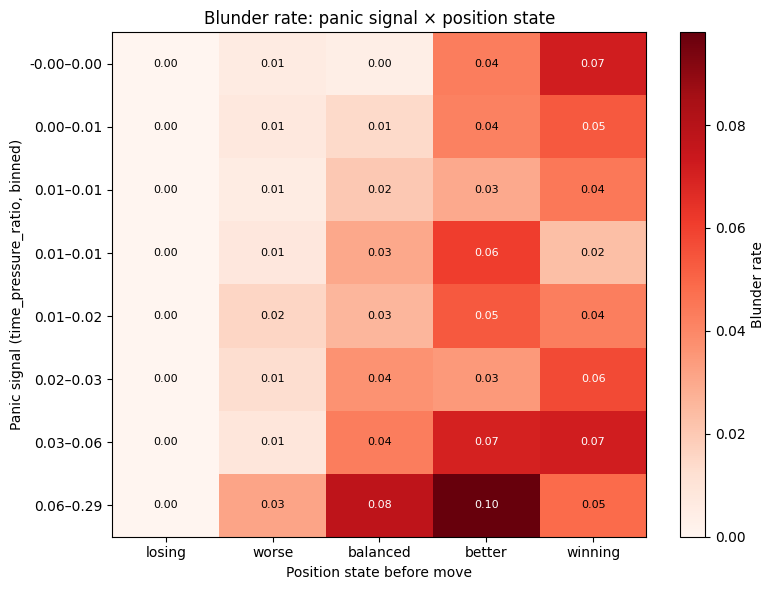

In [ ]:
pivot_wp = (
    df.groupby(["tpr_bucket", "wp_before_bucket"], observed=True)["is_blunder"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pivot_wp.values, aspect="auto", cmap="Reds")

ax.set_xticks(range(len(pivot_wp.columns)))
ax.set_xticklabels(pivot_wp.columns, rotation=0)
ax.set_yticks(range(len(pivot_wp.index)))
ax.set_yticklabels([f"{iv.left:.2f}–{iv.right:.2f}" for iv in pivot_wp.index])

ax.set_xlabel("Position state before move")
ax.set_ylabel("Panic signal (time_pressure_ratio, binned)")
ax.set_title("Blunder rate: panic signal × position state")

for i in range(pivot_wp.shape[0]):
    for j in range(pivot_wp.shape[1]):
        val = pivot_wp.values[i, j]
        if not np.isnan(val):
            ax.text(
                j, i, f"{val:.2f}", ha="center", va="center",
                color="white" if val > pivot_wp.values.max() / 2 else "black",
                fontsize=8
            )

fig.colorbar(im, ax=ax, label="Blunder rate")
plt.tight_layout()
plt.show()

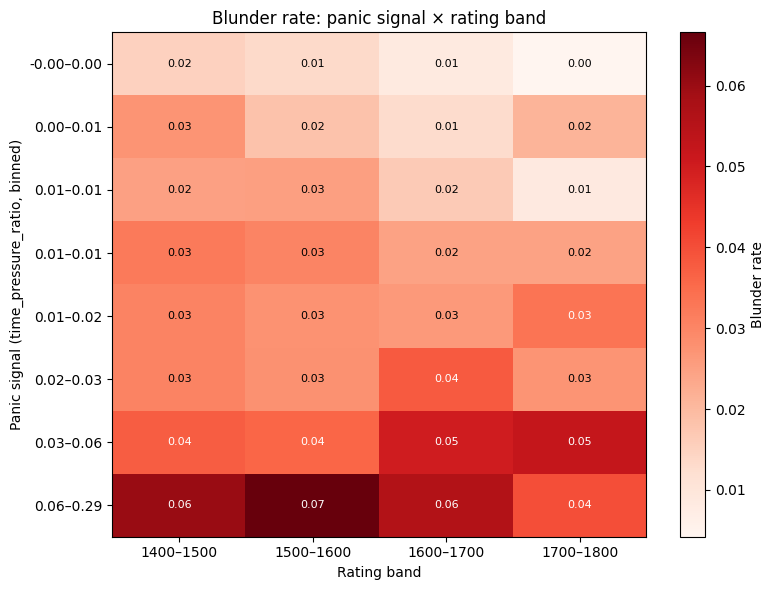

In [ ]:
pivot_elo = (
    df.groupby(["tpr_bucket", "elo_bucket"], observed=True)["is_blunder"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pivot_elo.values, aspect="auto", cmap="Reds")

ax.set_xticks(range(len(pivot_elo.columns)))
ax.set_xticklabels([f"{iv.left:.0f}–{iv.right:.0f}" for iv in pivot_elo.columns], rotation=0)
ax.set_yticks(range(len(pivot_elo.index)))
ax.set_yticklabels([f"{iv.left:.2f}–{iv.right:.2f}" for iv in pivot_elo.index])

ax.set_xlabel("Rating band")
ax.set_ylabel("Panic signal (time_pressure_ratio, binned)")
ax.set_title("Blunder rate: panic signal × rating band")

for i in range(pivot_elo.shape[0]):
    for j in range(pivot_elo.shape[1]):
        val = pivot_elo.values[i, j]
        if not np.isnan(val):
            ax.text(
                j, i, f"{val:.2f}", ha="center", va="center",
                color="white" if val > pivot_elo.values.max() / 2 else "black",
                fontsize=8
            )

fig.colorbar(im, ax=ax, label="Blunder rate")
plt.tight_layout()
plt.show()

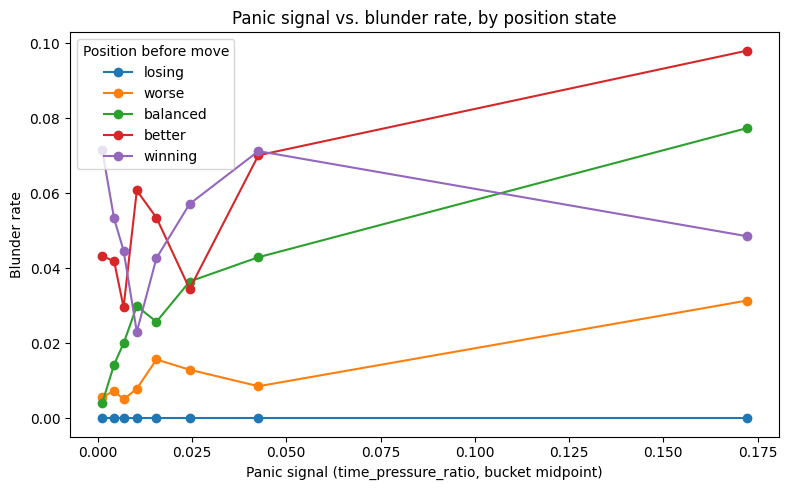

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

for wp_state, group in df.groupby("wp_before_bucket", observed=True):
    rate_by_bucket = group.groupby("tpr_bucket", observed=True)["is_blunder"].mean()
    x = [iv.mid for iv in rate_by_bucket.index]
    ax.plot(x, rate_by_bucket.values, marker="o", label=str(wp_state))

ax.set_xlabel("Panic signal (time_pressure_ratio, bucket midpoint)")
ax.set_ylabel("Blunder rate")
ax.set_title("Panic signal vs. blunder rate, by position state")
ax.legend(title="Position before move")
plt.tight_layout()
plt.show()

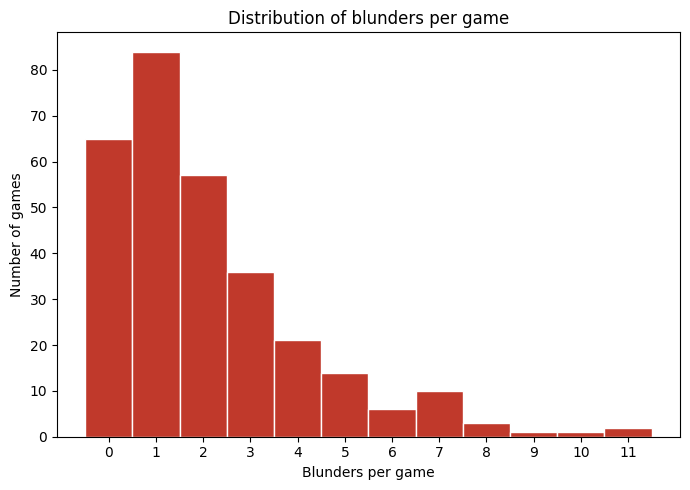

count    300.000000
mean       2.103333
std        2.097774
min        0.000000
25%        1.000000
50%        2.000000
75%        3.000000
max       11.000000
Name: is_blunder, dtype: float64
Games with 0 blunders: 21.7%
Games with 3+ blunders: 31.3%


In [ ]:
blunders_per_game = df.groupby("game_id")["is_blunder"].sum()

fig, ax = plt.subplots(figsize=(7, 5))
max_b = int(blunders_per_game.max())
ax.hist(
    blunders_per_game, bins=range(0, max_b + 2), align="left",
    edgecolor="white", color="#c0392b"
)
ax.set_xlabel("Blunders per game")
ax.set_ylabel("Number of games")
ax.set_title("Distribution of blunders per game")
ax.set_xticks(range(0, max_b + 1))
plt.tight_layout()
plt.show()

print(blunders_per_game.describe())
print(f"Games with 0 blunders: {(blunders_per_game == 0).mean():.1%}")
print(f"Games with 3+ blunders: {(blunders_per_game >= 3).mean():.1%}")

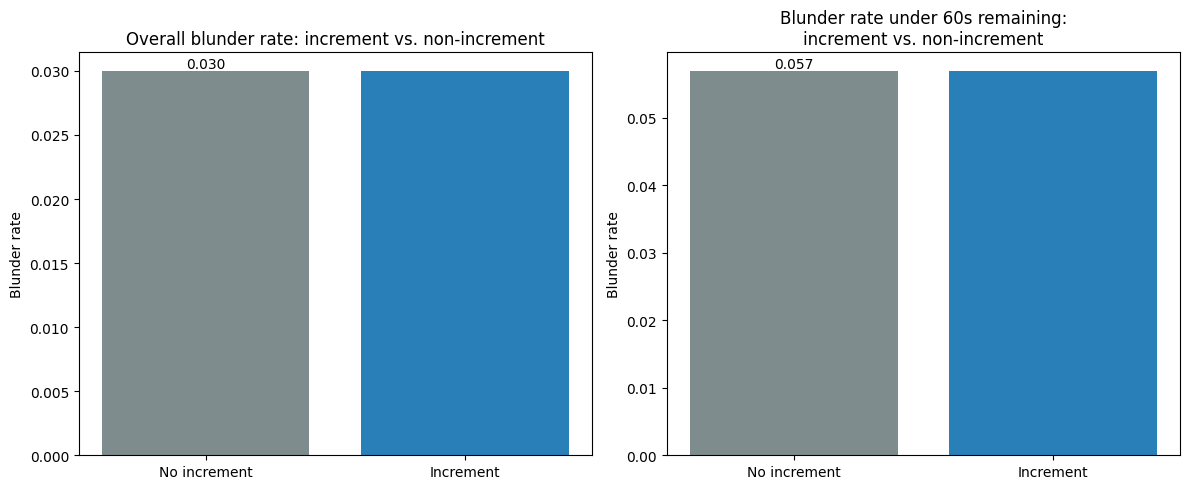

In [ ]:
def parse_increment(tc_str):
    """Parse Lichess TimeControl tag, e.g. '180+2' -> increment=2."""
    try:
        base, inc = tc_str.split("+")
        return int(inc) > 0
    except Exception:
        return False


# Reconstruct time_control for df from df_raw's game_headers
time_controls_map = (
    df_raw.groupby("game_id")["game_headers"]
    .first()
    .apply(lambda h: h.get("TimeControl"))
)
df["time_control"] = df["game_id"].map(time_controls_map)
df["has_increment"] = df["time_control"].apply(parse_increment)

overall_rate = df.groupby("has_increment")["is_blunder"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    ["No increment", "Increment"], overall_rate.values,
    color=["#7f8c8d", "#2980b9"]
)
axes[0].set_ylabel("Blunder rate")
axes[0].set_title("Overall blunder rate: increment vs. non-increment")
for i, v in enumerate(overall_rate.values):
    axes[0].text(i, v, f"{v:.3f}", ha="center", va="bottom")

# Restricted to late-game / low-clock moves, where increment should matter most
late_game = df[df["clock_seconds"] < 60]
late_rate = late_game.groupby("has_increment")["is_blunder"].mean()

axes[1].bar(
    ["No increment", "Increment"], late_rate.values,
    color=["#7f8c8d", "#2980b9"]
)
axes[1].set_ylabel("Blunder rate")
axes[1].set_title("Blunder rate under 60s remaining:\nincrement vs. non-increment")
for i, v in enumerate(late_rate.values):
    axes[1].text(i, v, f"{v:.3f}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

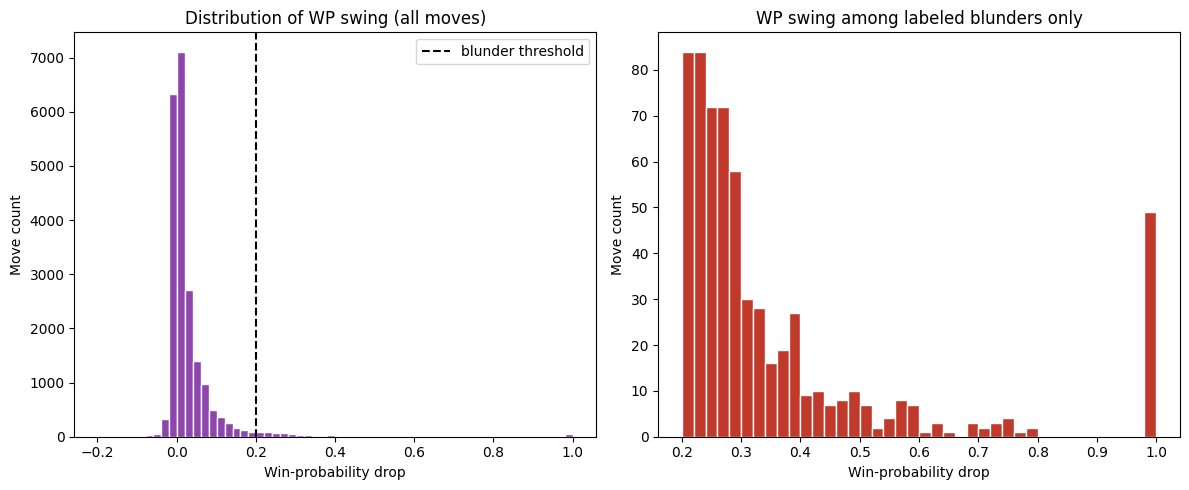

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df["wp_drop"], bins=60, color="#8e44ad", edgecolor="white")
axes[0].axvline(
    df.loc[df["is_blunder"] == 1, "wp_drop"].min(),
    color="black", linestyle="--", label="blunder threshold"
)
axes[0].set_xlabel("Win-probability drop")
axes[0].set_ylabel("Move count")
axes[0].set_title("Distribution of WP swing (all moves)")
axes[0].legend()

# Zoomed to just the blunders, to see severity spread among blunders themselves
blunder_drops = df.loc[df["is_blunder"] == 1, "wp_drop"]
axes[1].hist(blunder_drops, bins=40, color="#c0392b", edgecolor="white")
axes[1].set_xlabel("Win-probability drop")
axes[1].set_ylabel("Move count")
axes[1].set_title("WP swing among labeled blunders only")

plt.tight_layout()
plt.show()

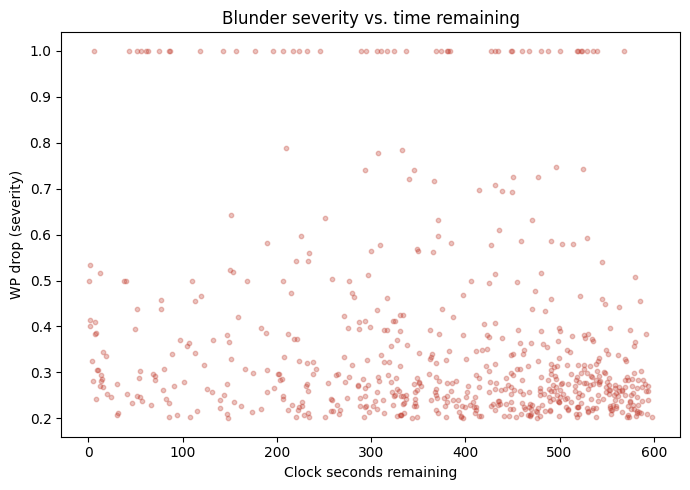

In [ ]:
# Severity vs. clock_seconds -- does time pressure predict how BAD
# the blunder is, not just whether one occurs
fig, ax = plt.subplots(figsize=(7, 5))
sample = df.loc[df["is_blunder"] == 1].sample(
    min(5000, (df["is_blunder"] == 1).sum()), random_state=0
)
ax.scatter(sample["clock_seconds"], sample["wp_drop"], alpha=0.3, s=10, color="#c0392b")
ax.set_xlabel("Clock seconds remaining")
ax.set_ylabel("WP drop (severity)")
ax.set_title("Blunder severity vs. time remaining")
plt.tight_layout()
plt.show()

/tmp/ipykernel_1431/3251148732.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby("game_id", group_keys=False).apply(moves_since_last_blunder)


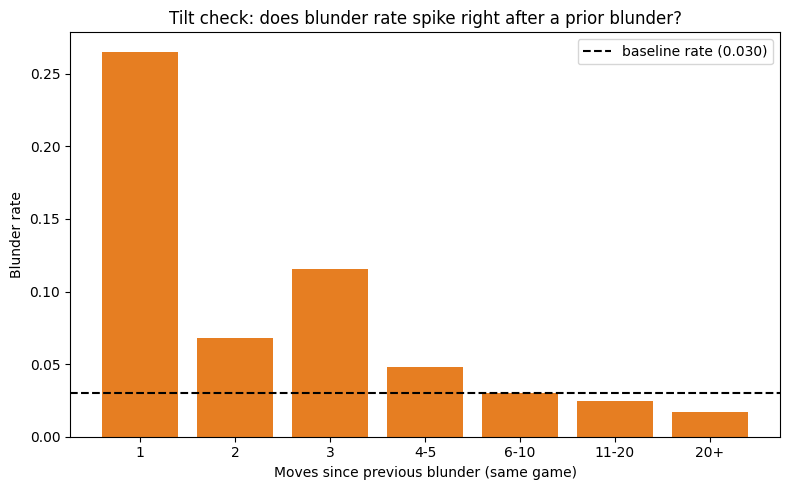

In [ ]:
def moves_since_last_blunder(group):
    result = np.full(len(group), np.nan)
    last = None
    for i in range(len(group)):
        if last is not None:
            result[i] = i - last
        if group["is_blunder"].values[i] == 1:
            last = i
    return pd.Series(result, index=group.index)


df = df.sort_values(["game_id", "move_num"])
df["moves_since_last_blunder"] = (
    df.groupby("game_id", group_keys=False).apply(moves_since_last_blunder)
)

gap_bucket = pd.cut(
    df["moves_since_last_blunder"],
    bins=[0, 1, 2, 3, 5, 10, 20, np.inf],
    labels=["1", "2", "3", "4-5", "6-10", "11-20", "20+"]
)
rate_by_gap = df.groupby(gap_bucket, observed=True)["is_blunder"].mean()
baseline = df["is_blunder"].mean()

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(rate_by_gap.index.astype(str), rate_by_gap.values, color="#e67e22")
ax.axhline(baseline, color="black", linestyle="--", label=f"baseline rate ({baseline:.3f})")
ax.set_xlabel("Moves since previous blunder (same game)")
ax.set_ylabel("Blunder rate")
ax.set_title("Tilt check: does blunder rate spike right after a prior blunder?")
ax.legend()
plt.tight_layout()
plt.show()

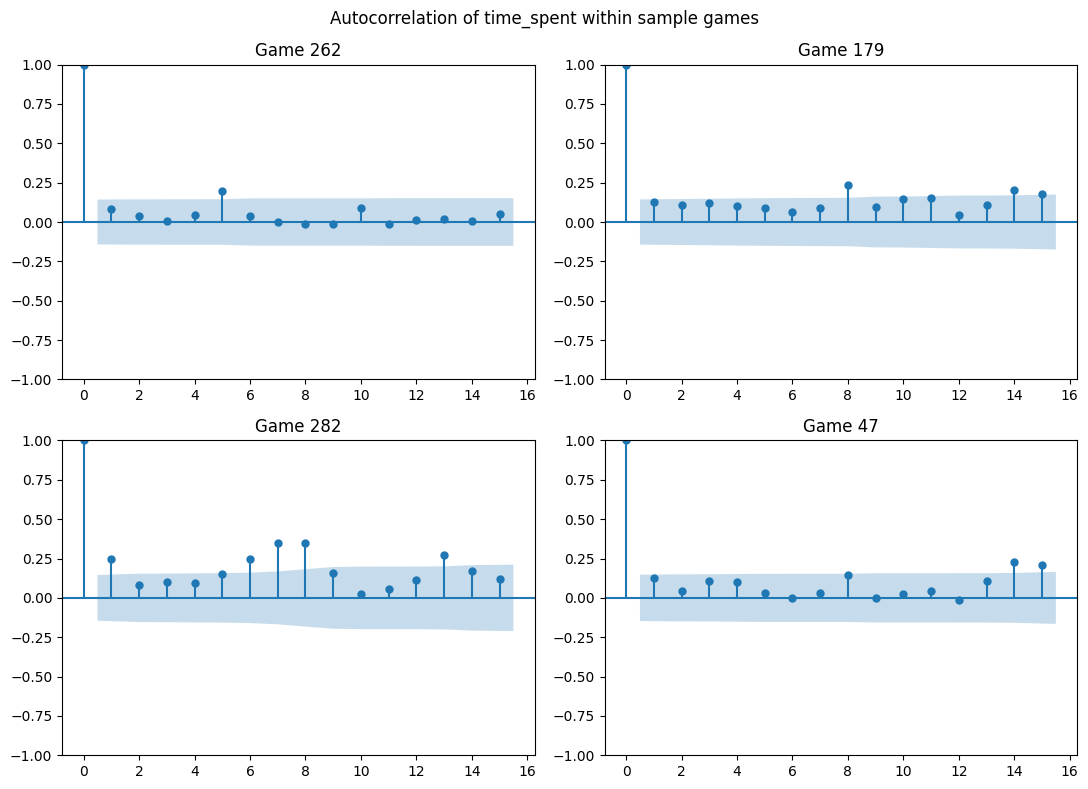

In [ ]:
sample_games = (
    df.groupby("game_id")["move_num"].count()
    .sort_values(ascending=False)
    .head(4).index
)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, gid in zip(axes.flat, sample_games):
    game_moves = df[df["game_id"] == gid].sort_values("move_num")
    plot_acf(game_moves["time_spent"].dropna(), ax=ax, lags=15, title=f"Game {gid}")
plt.suptitle("Autocorrelation of time_spent within sample games")
plt.tight_layout()
plt.show()

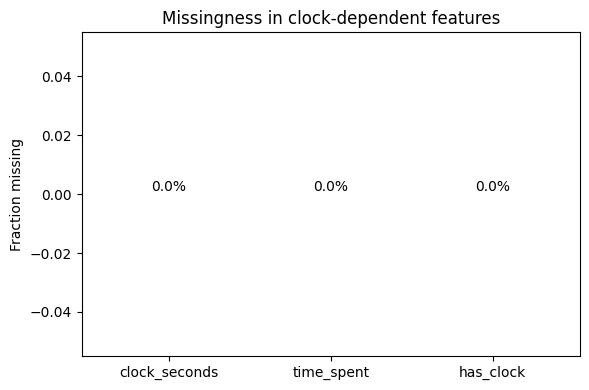

has_clock == False: 0.0% of moves


In [ ]:
missing_pct = df[["clock_seconds", "time_spent", "has_clock"]].isna().mean()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(missing_pct.index, missing_pct.values, color="#95a5a6")
ax.set_ylabel("Fraction missing")
ax.set_title("Missingness in clock-dependent features")
for i, v in enumerate(missing_pct.values):
    ax.text(i, v, f"{v:.1%}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

print(f"has_clock == False: {(df['has_clock'] == 0).mean():.1%} of moves")

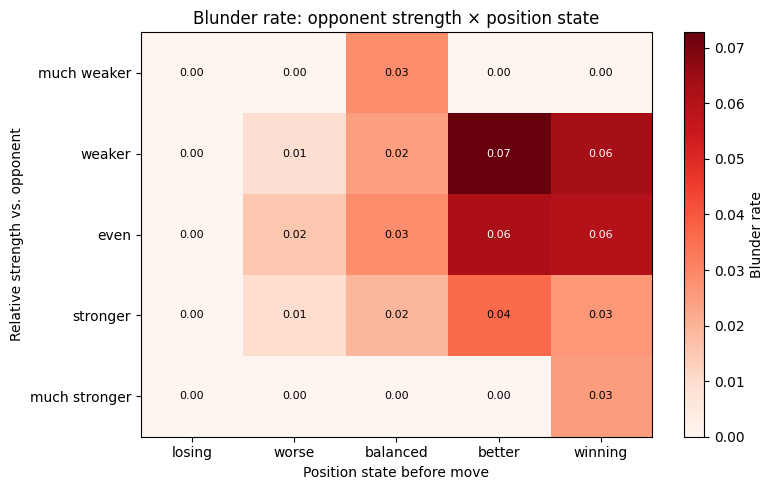

In [ ]:
elo_diff_bucket = pd.cut(
    df["elo_diff"], bins=[-1000, -200, -50, 50, 200, 1000],
    labels=["much weaker", "weaker", "even", "stronger", "much stronger"]
)

pivot = (
    df.assign(elo_diff_bucket=elo_diff_bucket)
    .groupby(["elo_diff_bucket", "wp_before_bucket"], observed=True)["is_blunder"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(pivot.values, aspect="auto", cmap="Reds")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel("Position state before move")
ax.set_ylabel("Relative strength vs. opponent")
ax.set_title("Blunder rate: opponent strength × position state")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(
                j, i, f"{val:.2f}", ha="center", va="center", fontsize=8,
                color="white" if val > np.nanmax(pivot.values) / 2 else "black"
            )
fig.colorbar(im, ax=ax, label="Blunder rate")
plt.tight_layout()
plt.show()

In [ ]:
import joblib

df.to_csv(PROJECT_DIR / "blunder_dataset_clean.csv", index=False)


print("Saved:")
print(f" - {PROJECT_DIR / 'blunder_dataset_clean.csv'}")


Saved:
 - /content/drive/MyDrive/chess-blunder-project/blunder_dataset_clean.csv
